In [1]:
from typing import TypedDict

from langchain_openrouter import ChatOpenRouter
from langgraph.graph import StateGraph

In [2]:
class CharacterRecommenderState(TypedDict):
    character_concept: str
    start_recommendation: str
    skills_recommendation: str
    equipment_recommendation: str
    summary: str

In [ ]:
from dotenv import load_dotenv

load_dotenv()

llm = ChatOpenRouter(
    model="nvidia/nemotron-3-super-120b-a12b:free"
)

In [4]:
from langchain_core.prompts import PromptTemplate

start_recommendation_template = PromptTemplate(
    input_variables=["character_concept"],
    template="""
You are a Skyrim character build advisor.
Based on the player's character concept below, recommend a suitable
starting approach to combat and exploration.

Character concept:
{character_concept}

Suggest a playstyle, preferred weapons or magic, and a general
approach to encounters. Keep the response concise and practical.
Treat this as a roleplaying recommendation rather than a strict
optimization problem.
"""
)

skills_recommendation_template = PromptTemplate(
    input_variables=["character_concept"],
    template="""
You are a Skyrim character build advisor specializing in skills.

Character concept:
{character_concept}

Recommend the most relevant Skyrim skill trees for this character.
For each skill, briefly explain why it fits the concept.
Prioritize a small number of core skills over listing every
potentially useful skill.

Keep the response concise and avoid inventing game mechanics.
"""
)

equipment_recommendation_template = PromptTemplate(
    input_variables=["character_concept"],
    template="""
You are a Skyrim equipment advisor.

Character concept:
{character_concept}

Recommend suitable equipment for this character, including weapons,
armor, and useful accessories where appropriate.

Explain briefly why each recommendation fits the character's playstyle.
Keep the equipment suggestions consistent with Skyrim's actual
game mechanics and avoid listing too many items.

If you are uncertain about a specific item, suggest a general
equipment category instead of inventing an item or its properties.

Keep the response concise and practical.
"""
)

summary_template = PromptTemplate(
    input_variables=[
        "character_concept",
        "start_recommendation",
        "skills_recommendation",
        "equipment_recommendation"
    ],
    template="""
You are a Skyrim character build advisor.

The player provided this character concept:
{character_concept}

Here are three independent recommendations:

Starting approach:
{start_recommendation}

Recommended skills:
{skills_recommendation}

Equipment:
{equipment_recommendation}

Combine these recommendations into a concise character profile.
Organize the response into three sections:
1. Playstyle
2. Core Skills
3. Equipments

Preserve the useful ideas from all three recommendations.
Resolve any obvious inconsistencies and avoid repeating information.
Do not introduce unnecessary new recommendations.
"""
)

In [5]:
from langchain_core.output_parsers import StrOutputParser

str_parser = StrOutputParser()

start_chain = start_recommendation_template | llm | str_parser
skills_chain = skills_recommendation_template | llm | str_parser
equipment_chain = equipment_recommendation_template | llm | str_parser
summary_chain = summary_template | llm | str_parser

In [6]:
def llm_start(state: CharacterRecommenderState):
    character_concept = state['character_concept']
    start_recommendation = start_chain.invoke({'character_concept':character_concept})

    return {'start_recommendation': start_recommendation}


def llm_skills(state: CharacterRecommenderState):
    character_concept = state['character_concept']
    skills_recommendation = skills_chain.invoke({'character_concept':character_concept})

    return {'skills_recommendation': skills_recommendation}


def llm_equipment(state: CharacterRecommenderState):
    character_concept = state['character_concept']
    equipment_recommendation = equipment_chain.invoke({'character_concept':character_concept})

    return {'equipment_recommendation': equipment_recommendation}


def llm_summary(state: CharacterRecommenderState):
    character_concept = state['character_concept']
    start_recommendation = state['start_recommendation']
    skills_recommendation = state['skills_recommendation']
    equipment_recommendation = state['equipment_recommendation']

    summary = summary_chain.invoke({
        'character_concept': character_concept,
        'start_recommendation': start_recommendation,
        'skills_recommendation': skills_recommendation,
        'equipment_recommendation': equipment_recommendation
    })

    return {'summary': summary}

In [7]:
from langgraph.graph import END, START

In [8]:
graph = StateGraph(CharacterRecommenderState)

# nodes
graph.add_node('llm_start', llm_start)
graph.add_node('llm_skills', llm_skills)
graph.add_node('llm_equipment', llm_equipment)
graph.add_node('llm_summary', llm_summary)

# edges
graph.add_edge(START, 'llm_start')
graph.add_edge(START, 'llm_skills')
graph.add_edge(START, 'llm_equipment')

graph.add_edge('llm_start', 'llm_summary')
graph.add_edge('llm_skills', 'llm_summary')
graph.add_edge('llm_equipment', 'llm_summary')

graph.add_edge('llm_summary', END)

# compile 
workflow = graph.compile()

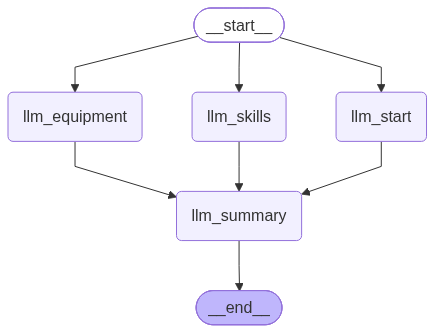

In [9]:
workflow

In [ ]:
character_concept = input('Enter your Skyrim character concept, please')

initial_state = {'character_concept': character_concept}

output_state = workflow.invoke(initial_state) # type: ignore

In [11]:
output_state

{'character_concept': 'I want to be a destruction expert Mage',
 'start_recommendation': '**Playstyle**  \n- Stay at mid‑range and let your spells do the work.  \n- Use a mix of burst damage (single‑target bolts) and area control (runes, wall spells) to keep enemies from closing in.  \n- When foes get too close, fall back with a quick‑cast defensive spell (e.g., *Flames* or *Ice Spike*) or a shield spell, then finish them off with a higher‑tier bolt.\n\n**Preferred Gear**  \n- **Primary:** Destruction staff tuned to your favored element (Fire\u202f→\u202f*Flames*\u202f→\u202f*Firebolt*, Frost\u202f→\u202f*Ice Spike*\u202f→\u202f*Icebolt*, Shock\u202f→\u202f*Lightning Bolt*\u202f→\u202f*Chain Lightning*).  \n- **Secondary:** A light melee weapon (dagger or short sword) enchanted with Absorb Health or Paralyze for emergency close‑quarters.  \n- **Apparel:** Robes with Fortify Destruction and Magicka Regen enchantments; optionally a piece with Mage Armor or Resist Fire/Frost/Shock for sur

In [13]:
from IPython.display import display, Markdown

for key, value in output_state.items():
    display(Markdown(f'{key.capitalize()}:\n{value}\n\n---'))

Character_concept:
I want to be a destruction expert Mage

---

Start_recommendation:
**Playstyle**  
- Stay at mid‑range and let your spells do the work.  
- Use a mix of burst damage (single‑target bolts) and area control (runes, wall spells) to keep enemies from closing in.  
- When foes get too close, fall back with a quick‑cast defensive spell (e.g., *Flames* or *Ice Spike*) or a shield spell, then finish them off with a higher‑tier bolt.

**Preferred Gear**  
- **Primary:** Destruction staff tuned to your favored element (Fire → *Flames* → *Firebolt*, Frost → *Ice Spike* → *Icebolt*, Shock → *Lightning Bolt* → *Chain Lightning*).  
- **Secondary:** A light melee weapon (dagger or short sword) enchanted with Absorb Health or Paralyze for emergency close‑quarters.  
- **Apparel:** Robes with Fortify Destruction and Magicka Regen enchantments; optionally a piece with Mage Armor or Resist Fire/Frost/Shock for survivability.  
- **Consumables:** Potions of Restore Magicka, Fortify Destruction, and Resistance (matching the element you’re using most).

**General Encounter Approach**  
1. **Scout** – Use *Detect Life* or *Magic Detection* to spot enemies before they see you.  
2. **Open with a Rune** – Place a *Fire Rune*, *Frost Rune*, or *Shock Rune* at a choke point or enemy path; it deals damage when stepped on and can interrupt melee rushes.  
3. **Follow with a Bolt** – While the enemy is distracted by the rune, unleash your highest‑damage single‑target bolt (*Firebolt*, *Icebolt*, or *Lightning Bolt*).  
4. **Switch Elements if Needed** – If an enemy shows strong resistance, swap to another element (e.g., use Shock against heavily armored foes, Fire against unarmored beasts).  
5. **Control the Crowd** – For groups, alternate between *Wall of Flames*/*Wall of Ice* and *Chain Lightning* to hit multiple targets while keeping distance.  
6. **Finish Up** – When low on magicka, fall back, drink a potion, and resume. Use your dagger only if you’re forced into melee; otherwise, keep the fight spell‑centric.

**Quick Tips**  
- Prioritize the *Impact* perk (stagger enemies with dual‑cast) to keep melee foes at bay.  
- Invest in *Novice*/*Adept* Destruction cost‑reduction perks early; later take *Intense Flames*/*Deep Freeze*/*Intense Lightning* for extra damage.  
- Enchant gear with Fortify Magicka and Fortify Destruction to sustain longer fights.  
- Use followers or summoned familiars (e.g., *Flame Atronach*) as a distraction while you rain destruction from safety.  

Strike fast, control the battlefield, and let your elemental fury do the talking. Enjoy the blaze (or chill, or spark)!

---

Skills_recommendation:
**Core skill trees for a Destruction‑focused mage**

| Skill | Why it fits the concept |
|-------|--------------------------|
| **Destruction** | Directly governs fire, frost, and shock spells – the bread‑and‑butter damage output of a mage who wants to specialize in destructive magic. |
| **Restoration** | Provides healing and wards to keep you alive while you channel high‑cost Destruction spells; essential survivability for a frontline caster. |
| **Enchanting** | Lets you imbue gear with Fortify Destruction, Fortify Magicka, and reduced spell cost enchantments, dramatically increasing your spell‑casting efficiency. |
| **Alteration** | Offers magical defenses (e.g., Magic Resistance, Oakflesh) and utility spells like Transmute, letting you bolster survivability without relying solely on Restoration. |
| **Conjuration (optional)** | Summons Flame, Frost, or Storm Atronachs to act as damage dealers or tanks, complementing your own Destruction barrage when you need extra firepower. |

Focus first on maxing **Destruction** and **Restoration**, then invest in **Enchanting** to gear‑boost your magicka and reduce spell costs. Add **Alteration** for supplemental protection, and consider **Conjuration** if you want summoned allies to augment your destructive assaults.

---

Equipment_recommendation:
**Weapon** – *Destruction staff* (choose the element that matches enemy weaknesses: Staff of Flames → fire, Staff of Frostbite → frost, Staff of Lightning → shock).  
*Why:* A staff casts the selected Destruction spell automatically, letting you deal consistent damage without draining your magicka pool – ideal for a pure‑damage mage who wants to stay in the fight longer.

**Armor (Light)** – *Archmage’s Robes* + *Archmage’s Hood* (plus matching boots/gauntlets if you have them).  
*Why:* The Archmage set gives a flat boost to Destruction damage (+15 %) and a sizable magicka bonus (+25 magicka). Light armor keeps encumbrance low so you can move quickly while casting, and the set’s enchantments synergize directly with your spell damage.

**Accessories**  
- *Amulet of Julianos* – +15 % magicka regeneration.  
- *Ring of Erudite* – +15 % magicka regeneration (stacks with the amulet).  
- *Circlet of the Magi* (unique headgear from the College questline) – +20 % magicka regeneration.  
*Why:* These items raise your magicka regen rate, letting you sustain high‑cost Destruction spells (Firebolt, Ice Spike, Lightning Bolt) for longer periods before needing to wait or use potions.

**Optional backup** – A lightweight dagger (e.g., *Blade of Woe* or any common dagger) for emergencies when you’re caught in melee.  
*Why:* It adds negligible weight and gives you a quick, low‑cost melee option without compromising your mage focus.

---

Summary:
**Playstyle**  
- Fight from mid‑range, letting your spells do the bulk of the work.  
- Open engagements with a Destruction rune (Fire, Frost or Shock) placed on a choke point; it damages and staggers enemies that step on it.  
- While the rune holds their attention, unleash your highest‑damage single‑target bolt (Firebolt, Icebolt or Lightning Bolt).  
- For groups, alternate wall spells (Wall of Flames/Ice) with Chain Lightning to hit multiple foes while staying back.  
- Switch elements on the fly if an enemy shows strong resistance (e.g., Shock vs. heavily armored, Fire vs. unarmored beasts).  
- If a foe closes, fall back with a quick‑cast defensive spell (Flames, Ice Spike, or a ward) or raise a shield, then finish with a higher‑tier bolt.  
- Take the **Impact** perk (dual‑cast stagger) early to keep melee threats at bay, and invest in Novice/Adept cost‑reduction perks before moving to Intense Flames/Deep Freeze/Intense Lightning for extra damage.  
- Sustain fights with Fortify Destruction and Fortify Magicka enchants, magicka‑regen potions, and occasional use of a summoned Flame/Frost/Storm Atronach or a follower as a distraction.  
- Keep a light dagger (Absorb Health or Paralyze) for emergency melee, but aim to stay spell‑centric.

**Core Skills**  
1. **Destruction** – Primary damage tree; focus on mastering bolts, runes, walls, and chain spells.  
2. **Restoration** – Healing and wards for survivability while casting high‑cost Destruction spells.  
3. **Enchanting** – Create gear with Fortify Destruction, Fortify Magicka, and reduced spell‑cost enchants to boost efficiency.  
4. **Alteration** – Magical defenses (Magic Resistance, Oakflesh) and utility spells that supplement your survivability without relying solely on Restoration.  
5. **Conjuration (optional)** – Summon Flame, Frost, or Storm Atronachs to act as extra damage dealers or tanks when you need added firepower.  

*Progression:* Max Destruction first, then Restoration. Next, invest in Enchanting to improve your gear. Add Alteration for protection, and pick up Conjuration only if you want summoned allies.

**Equipments**  
- **Weapon:** Destruction staff tuned to your preferred element (Staff of Flames → Fire, Staff of Frostbite → Frost, Staff of Lightning → Shock).  
- **Secondary:** Light dagger (e.g., Blade of Woe or any common dagger) enchanted with Absorb Health or Paralyze for close‑quarters emergencies.  
- **Armor:** Light‑armor robes – Archmage’s Robes + Archmage’s Hood (plus matching boots/gauntlets if available) for +15 % Destruction damage and +25 magicka while keeping encumbrance low.  
- **Accessories:** Amulet of Julianos (+15 % magicka regen), Ring of Erudite (+15 % magicka regen, stacks), Circlet of the Magi (+20 % magicka regen) – together they greatly extend spell‑casting endurance.  
- **Consumables:** Potions of Restore Magicka, Fortify Destruction, and elemental Resistance (matching the element you’re using most).  
- **Optional Utility:** A summoned Flame/Frost/Storm Atronach (via Conjuration) to act as a distraction or extra damage source while you rain destruction from safety.  

This profile merges the mid‑range, spell‑focused playstyle, the essential skill trees, and the gear that maximizes Destruction damage, magicka sustainability, and survivability without introducing extraneous advice.

---